In [1]:
import sys
import numpy as np
import pandas as pd
from typing import List
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def load_sample_data():
    ratings_data = {
        'UserId': [1, 1, 1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 4],
        'MovieId': [1, 2, 3, 4, 5, 1, 3, 5, 2, 4, 5, 1, 2, 3, 5],
        'Rating': [5, 3, 4, 2, 5, 4, 5, 3, 2, 4, 5, 3, 4, 2, 5],
        'Timestamp': [1256677221, 1256677456, 1256677471, 1256677460, 1256677264,
                      1256677222, 1256677457, 1256677472, 1256677461, 1256677265,
                      1256677223, 1256677458, 1256677473, 1256677462, 1256677266]
    }

    # Movie information
    items_data = {
        'MovieId': [1, 2, 3, 4, 5],
        'title': ['Toy Story', 'Jumanji', 'Grumpier Old Men', 'Waiting to Exhale', 'Father of the Bride'],
        'genres': ['Animation|Children|Comedy', 'Adventure|Children|Fantasy',
                   'Comedy|Romance', 'Comedy|Drama', 'Comedy']
    }

    # User information
    users_data = {
        'UserId': [1, 2, 3, 4],
        'Age': [24, 53, 23, 40],
        'Gender': ['M', 'F', 'M', 'F'],
        'Occupation': ['technician', 'other', 'writer', 'technician'],
        'ZipCode': ['85711', '94043', '32067', '43537']
    }

    df_rating = pd.DataFrame(ratings_data)
    df_items = pd.DataFrame(items_data)
    df_users = pd.DataFrame(users_data)

    # Create rating matrix
    df_matrix = df_rating.merge(df_users, on='UserId', how='inner').merge(df_items, on='MovieId', how='inner')[["UserId","title", "Rating"]]

    n_users = len(df_users)
    n_items = len(df_items)

    return df_rating, df_users, df_items,df_matrix,  n_users, n_items


In [3]:
df_rating, df_users, df_items, df_matrix, n_users, n_items = load_sample_data()

In [4]:
print("Data loaded successfully!")
print(f"Number of users: {n_users}")
print(f"Number of items: {n_items}")
print("\nRating matrix:")
df_matrix

Data loaded successfully!
Number of users: 4
Number of items: 5

Rating matrix:


,UserId,title,Rating
0,1,Toy Story,5
1,1,Jumanji,3
2,1,Grumpier Old Men,4
3,1,Waiting to Exhale,2
4,1,Father of the Bride,5
5,2,Toy Story,4
6,2,Grumpier Old Men,5
7,2,Father of the Bride,3
8,3,Jumanji,2
9,3,Waiting to Exhale,4


In [5]:
def get_most_popular_movies(df_rating, df_items, top_k=5):
    """Get the most popular movies based on number of ratings"""

    movie_stats = df_rating.groupby('MovieId')['Rating'].agg(rating_count='count', avg_rating='mean').reset_index()
    popular_movies = df_items.merge(movie_stats, on='MovieId', how='inner') \
                             .sort_values(['rating_count', 'avg_rating'], ascending=False)

    return popular_movies.head(top_k)

def get_highest_rated_movies(df_rating, df_items, min_ratings=2, top_k=5):
    """Get the highest rated movies with minimum number of ratings"""

    movie_stats = df_rating.groupby('MovieId')['Rating'].agg(rating_count='count', avg_rating='mean').reset_index()
    movie_stats = movie_stats[movie_stats['rating_count'] >= min_ratings]
    highest_rated = df_items.merge(movie_stats, on='MovieId', how='inner') \
                            .sort_values(['avg_rating', 'rating_count'], ascending=False)

    return highest_rated.head(top_k)

In [6]:
print("\n" + "="*50)
print("MOST POPULAR MOVIES (by number of ratings):")
print("="*50)
popular_movies = get_most_popular_movies(df_rating, df_items)
print(popular_movies[['title', 'genres', 'rating_count', 'avg_rating']])




MOST POPULAR MOVIES (by number of ratings):
                 title                      genres  rating_count  avg_rating
4  Father of the Bride                      Comedy             4    4.500000
0            Toy Story   Animation|Children|Comedy             3    4.000000
2     Grumpier Old Men              Comedy|Romance             3    3.666667
1              Jumanji  Adventure|Children|Fantasy             3    3.000000
3    Waiting to Exhale                Comedy|Drama             2    3.000000


In [7]:
print("\n" + "="*50)
print("HIGHEST RATED MOVIES (min 2 ratings):")
print("="*50)
highest_rated = get_highest_rated_movies(df_rating, df_items, min_ratings=2)
print(highest_rated[['title', 'genres', 'rating_count', 'avg_rating']])


HIGHEST RATED MOVIES (min 2 ratings):
                 title                      genres  rating_count  avg_rating
4  Father of the Bride                      Comedy             4    4.500000
0            Toy Story   Animation|Children|Comedy             3    4.000000
2     Grumpier Old Men              Comedy|Romance             3    3.666667
1              Jumanji  Adventure|Children|Fantasy             3    3.000000
3    Waiting to Exhale                Comedy|Drama             2    3.000000


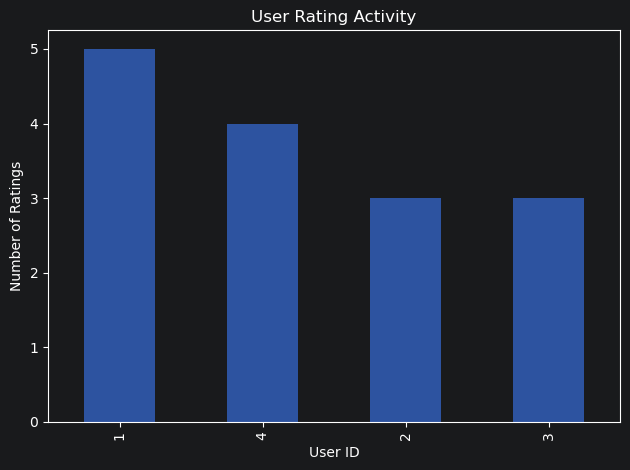

In [8]:
user_activity = df_rating['UserId'].value_counts()
user_activity.plot(kind='bar', alpha=0.7)
plt.title('User Rating Activity')
plt.xlabel('User ID')
plt.ylabel('Number of Ratings')

plt.tight_layout()
plt.show()

In [9]:
print("\nDataset Statistics:")
print(f"Total ratings: {len(df_rating)}")
print(f"Average rating: {df_rating['Rating'].mean():.2f}")
print(f"Rating sparsity: {1 - len(df_rating) / (n_users * n_items):.2%}")

print("\n" + "="*50)
print("RECOMMENDATIONS FOR NEW USER:")
print("="*50)
print("Since we don't know anything about the new user,")
print("we recommend the most popular and highest rated movies:")

print("\nTop recommendations:")
for i, (_, movie) in enumerate(popular_movies.iterrows(), 1):
    print(f"{i}. {movie['title']} (Popularity: {movie['rating_count']} ratings, Avg: {movie['avg_rating']:.1f})")


Dataset Statistics:
Total ratings: 15
Average rating: 3.73
Rating sparsity: 25.00%

RECOMMENDATIONS FOR NEW USER:
Since we don't know anything about the new user,
we recommend the most popular and highest rated movies:

Top recommendations:
1. Father of the Bride (Popularity: 4 ratings, Avg: 4.5)
2. Toy Story (Popularity: 3 ratings, Avg: 4.0)
3. Grumpier Old Men (Popularity: 3 ratings, Avg: 3.7)
4. Jumanji (Popularity: 3 ratings, Avg: 3.0)
5. Waiting to Exhale (Popularity: 2 ratings, Avg: 3.0)
